<center>
<img src="https://2627moodle.isel.pt/pluginfile.php/1167016/mod_page/intro/image%20%2827%29.png" width="250">
<h3>Licenciatura em Engenharia Informática e Multimédia</h3><br>
Ano Letivo 2026/2027<br>
<h3>Processamento de Imagem e Visão (PIV)</h3>
<h3>1º Trabalho Prático – Contagem e Classificação de Peças de Lego Retangulares</h3> 


<center> 
<br>
Filipe Mendes <b>48628</b><br>
Mª Luísa Melo e Sampaio <b>50799</b><br>
Turma 52D<br><br>
Docente: <b> Tiago Gonçalves</b><br>
8 de Novembro de 2025
</center>
</center>

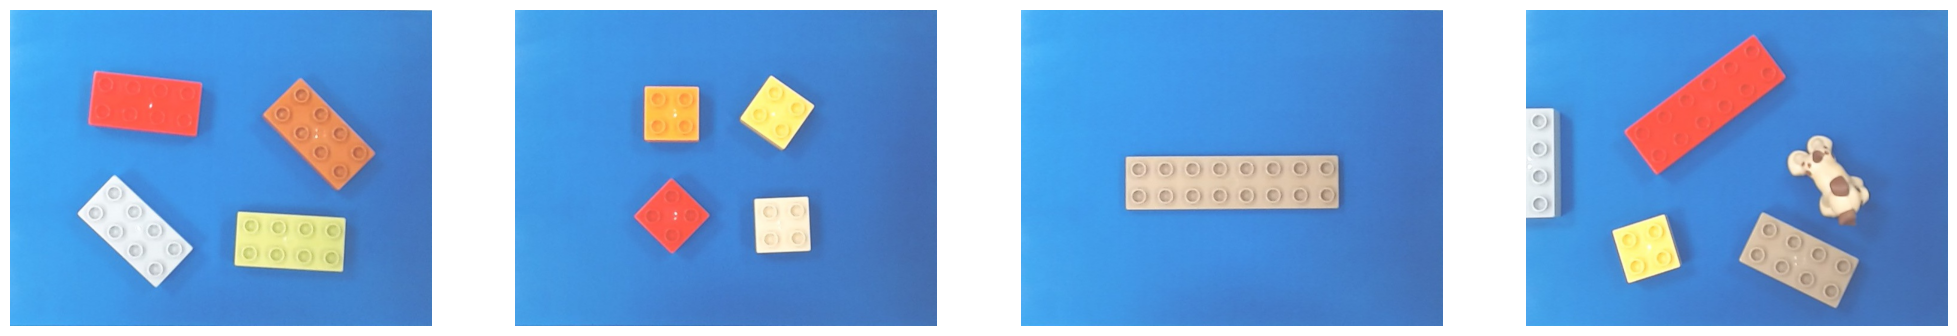

In [29]:
import cv2  
import matplotlib.pyplot as plt  
import numpy as np  
import os  

images_dir = './validacao/'

#Cria uma lista com os nomes dos ficheiros de imagem que terminam em '.jpg'
image_files = [f for f in os.listdir(images_dir) if f.endswith('.jpg')]

readImgs = [] #Lista de imagems originais em BGR
rgbImgs = [] #Lista de imagems em formato RGB

x = 1  
plt.figure(figsize=(25,20))

#Percorre a lista de imagens originais no ficheiro onde estão guardadas
for i in range(len(image_files)):
    image_path = os.path.join(images_dir, image_files[i])  
    image = cv2.imread(image_path)  
    readImgs.append(image)
    
    #Converte a imagem de BGR para RGB
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)   
    rgbImgs.append(rgb_image)
    
    #Exibição das imagens em formato RGB
    plt.subplot(4, 4, x)
    plt.imshow(rgbImgs[i]) 
    plt.axis('off')  
    x += 1

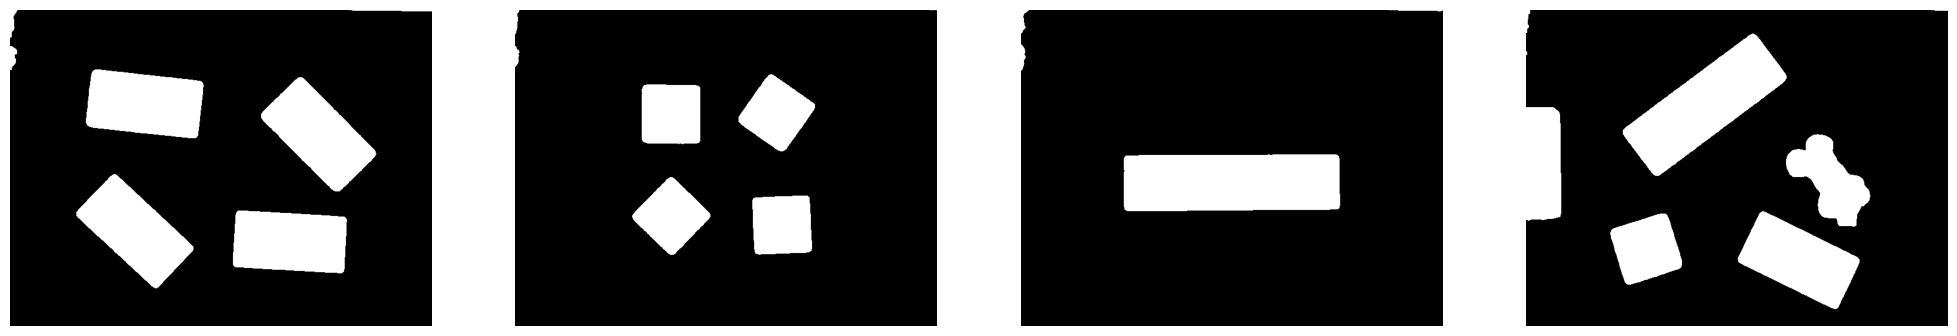

In [30]:
binImgs = []  #Lista de imagens binarizadas

#Função para binarizar as imagens através de um threshold no canal vermelho
def bin_red_chanel(img):
    #Aplica um desfoque gaussiano ao canal vermelho da imagem
    aux = cv2.GaussianBlur(img[:,:,2], (5,5), 3)
    #Aplica um threshold no canal vermelho da imagem RGB
    _, imgBinarizada = cv2.threshold(aux, 85, 255, cv2.THRESH_BINARY)
     
    return imgBinarizada  

x = 1  
plt.figure(figsize=(25,20))

for i in range(len(readImgs)):
    #Aplica a função de binarização a cada imagem da lista de imagens RGB
    binImgs.append(bin_red_chanel(readImgs[i]))
    
    #Exibição das imagens binarizadas
    plt.subplot(4, 4, x)
    plt.imshow(binImgs[i], cmap='gray')  
    plt.axis('off')  
    x += 1  


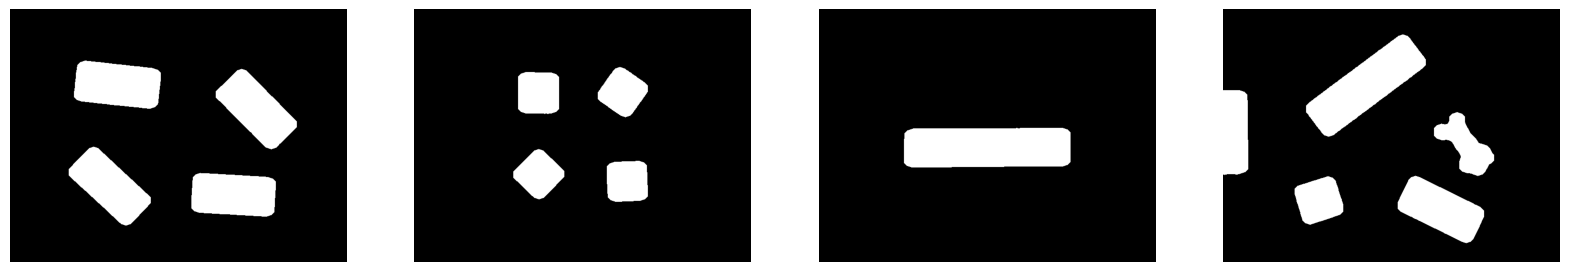

In [31]:
betterImgs = []  #Lista de imagens após melhoramento das mesmas

#Função para melhorar a imagem binarizada
def get_better_image(img):
    #Operação morfológica de fechamento para preencher buracos na imagem
    closed  = cv2.morphologyEx(img, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
    #Erosão para remover ruído; utiliza um elemento estruturante elíptico de 15x15 e 3 iterações
    eroded = cv2.erode(closed, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)), iterations=3)
    #Dilatação para restaurar a forma original da imagem após a erosão; utiliza um elemento estruturante elíptico de 11x11 e 3 iterações
    dilated = cv2.dilate(eroded, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11,11)), iterations=3)
    return dilated  # Retorna a imagem melhorada

x = 1  
plt.figure(figsize=(20,16))

for i in range(len(binImgs)):
    #Aplica a função de melhoria a cada imagem binarizada da lista
    betterImgs.append(get_better_image(binImgs[i]))

    plt.subplot(4, 4, x)
    plt.imshow(betterImgs[i], cmap='gray') 
    plt.axis('off')  
    x += 1  


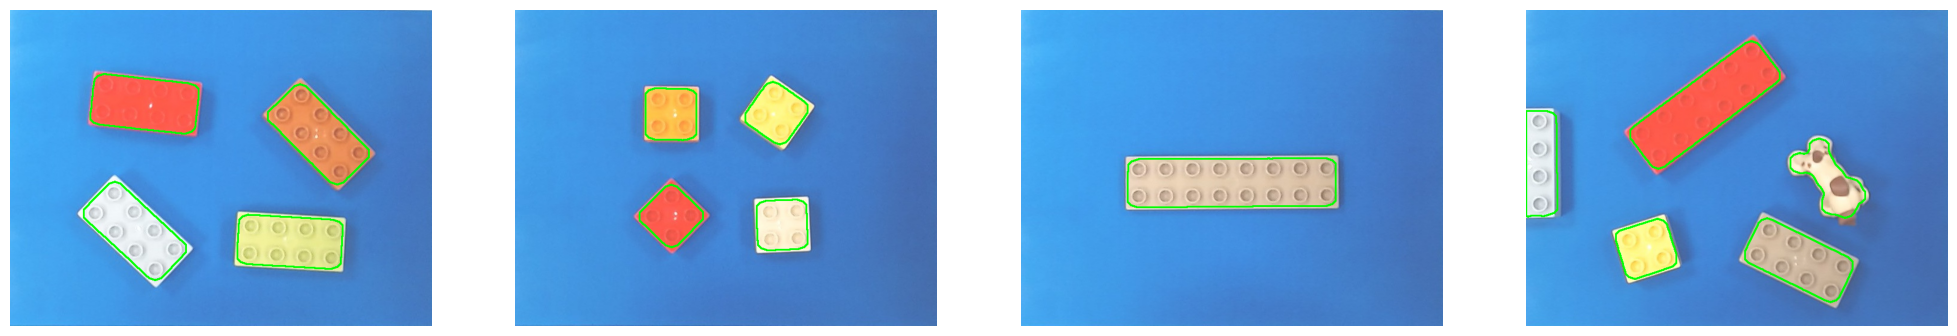

In [32]:
contourImgs = []  #Lista de imagens com os contornos
contourList = []  #Lista de contornos das peças de cada imagem

#Função para encontrar contornos nas imagens melhoradas
def find_contours(better_image):
    #Encontra os contornos da imagem usando cv2.findContours
    #RETR_EXTERNAL devolve apenas os contornos exteriores; CHAIN_APPROX_SIMPLE reduz o número de pontos
    contours, hierarchy = cv2.findContours(better_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return contours, hierarchy  

x = 1
plt.figure(figsize=(25,20))

for i in range(len(betterImgs)):
    #Encontra os contornos na imagem melhorada
    contours, hierarchy = find_contours(betterImgs[i])
    contourList.append(contours)  

    #Cópia da imagem original para desenhar os contornos
    original_img = np.copy(rgbImgs[i])    
    
    #Desenha os contornos na imagem original
    cv2.drawContours(original_img, contours, -1, (0, 255, 0), 2)
    contourImgs.append(original_img)  # Adiciona a imagem com contornos à lista
    
    plt.subplot(4, 4, x)
    plt.imshow(contourImgs[i])  
    plt.axis('off')  
    x += 1  

In [ ]:
#Função para classificar uma peça de LEGO com base nas suas dimensões
def classify_lego_piece(w, h):
    #Calcula o aspect ratio como a razão entre o lado maior e o lado menor (sempre >= 1)
    aspect_ratio = max(w, h) / min(w, h)
    
    if w < 60 or h < 60:
        return "Invalid"
    
    if aspect_ratio < 1.25:
        return "2x2"
    
    if 1.82 <= aspect_ratio <= 2.42:
        return "2x4"
    
    if 2.42 < aspect_ratio <= 3.57:
        return "2x6"
    
    if aspect_ratio > 3.57:
        return "2x8"
    
    return "Invalid"


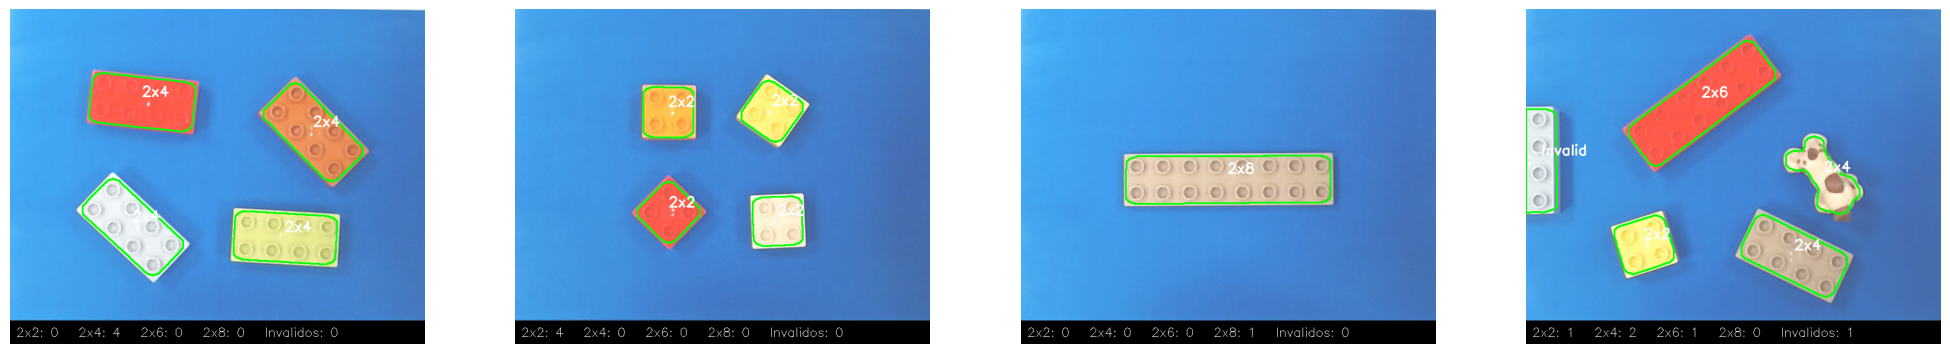

In [34]:
classImgs = []  #Lista de imagens classificadas e com labels atribuidos

#Função para classificar e atribuir labels aos componentes de LEGO na imagem original
def classify_and_label_components(orig_image, contours):
    #Contadores para cada tipo de peça de LEGO e para peças inválidas
    x2Count = 0
    x4Count = 0 
    x6Count = 0
    x8Count = 0
    invalidCount = 0
    
    for contour in contours:
        area = cv2.contourArea(contour)  #Calcula a área do contorno
        if area < 1000:  #Ignora contornos com área inferior a 1000
            continue
        
        rect = cv2.minAreaRect(contour)  #Obtém um retângulo mínimo que envolve o contorno
        (x, y), (w, h), angle = rect  #Extrai as coordenadas e dimensões do retângulo
        w, h = sorted([w, h])  #Ordena a largura e altura para estas não serem trocadas a calcular o aspect ratio

        #Aproxima o contorno para uma forma poligonal
        epsilon = 0.02 * cv2.arcLength(contour, True) 
        approx = cv2.approxPolyDP(contour, epsilon, True)

        if len(approx) != 0:  
            #Classifica a peça de LEGO com base na largura e altura
            label = classify_lego_piece(w, h)
            
            # Atualiza o contador com base na classificação
            if label == "2x2":
                x2Count += 1
            elif label == "2x4":
                x4Count += 1
            elif label == "2x6":
                x6Count += 1
            elif label == "2x8":
                x8Count += 1
            else:
                label = "Invalid"
                invalidCount += 1
        
            #Desenha o contorno na imagem original
            cv2.drawContours(orig_image, [contour], -1, (0, 255, 0), 2)
            
            #Adiciona o label da peça na imagem
            cv2.putText(orig_image, label, (int(x), int(y) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

    #Cria uma faixa preta por baixo da imagem para escrever a contagem sem tapar as peças
    faixa = np.zeros((40, orig_image.shape[1], 3), dtype=np.uint8)
    cv2.putText(faixa, f"2x2: {x2Count}   2x4: {x4Count}   2x6: {x6Count}   2x8: {x8Count}   Invalidos: {invalidCount}",
                (10, 27), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 1)
    #Junta a faixa à imagem original
    orig_image = np.vstack([orig_image, faixa])

    return orig_image

plt.figure(figsize=(25, 20))
x = 1  

for i in range(len(contourImgs)):
    
    #Chama e itera sobre a lista de contornos e de imagens RGB simultâneamente
    labeled_image = classify_and_label_components(rgbImgs[i].copy(), contourList[i])
    original_img = np.copy(rgbImgs[i])      
    classImgs.append(labeled_image)  
    
    plt.subplot(4, 4, x)
    plt.imshow(classImgs[i]) 
    plt.axis('off')  
    x += 1  


In [35]:
folder_name = "output_images"  #Nome da pasta onde as imagens serão guardadas

#Verifica se a pasta já existe; se não, cria-a
if not os.path.exists(folder_name):
    os.makedirs(folder_name) 

for i, image in enumerate(classImgs):
    #Define o path do arquivo onde a imagem será guardada, nomeando-a com base no indice
    image_path = os.path.join(folder_name, f"image_{i}.jpg") 
    cv2.imwrite(image_path, np.copy(image[:, :, ::-1]))